In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from collections import Counter
from itertools import combinations, permutations

1.a

In [ ]:
def deterministic_lotka_volterra(p_1_o, p_2_o, alpha, beta, gamma, delta, t_max, dt):
    """
    simulates the L-V predator-prey model using Euler's integration
    follows methods from sir in class 13 notebook and sayama scripts

    Parameters:
    p_1_o: Initial prey population.
    p_2_o: Initial predator population.
    alpha: Prey reproduction rate.
    beta: Predation rate.
    gamma: Predator death rate.
    delta: Predator growth rate given food.
    t_max: Final time of the simulation (simulation runs from t=0 to t=t_max).
    dt: Time step size.

    The populations evolve according to:
        - dp_1/dt = alpha * p_1 - beta * p_1 * p_2
        - dp_2/dt = delta * p_1 * p_2 - gamma * p_2
    """

    # Number of steps needed to go from t=0 to t=t_max
    n_steps = int(round(t_max / dt))

    # arrays for storing time and populations at each time step
    t = np.linspace(0, t_max, n_steps + 1)
    p_1 = np.zeros(n_steps + 1)
    p_2 = np.zeros(n_steps + 1)
    p_1[0] = p_1_o
    p_2[0] = p_2_o

    # Euler update taken from Sayama, predator-prey-continuous.py, see .tex for cite
    # with variables renamed: x -> p_1, y -> p_2, a/b/c/d -> alpha/beta/gamma/delta, Dt -> dt.
    for i in range(n_steps):
        # Prey: reproduction minus predation
        p_1[i+1] = p_1[i] + (alpha * p_1[i] - beta * p_1[i] * p_2[i]) * dt

        # Predators: growth from eating prey minus death
        p_2[i+1] = p_2[i] + (delta * p_1[i] * p_2[i] - gamma * p_2[i]) * dt

    return t, p_1, p_2

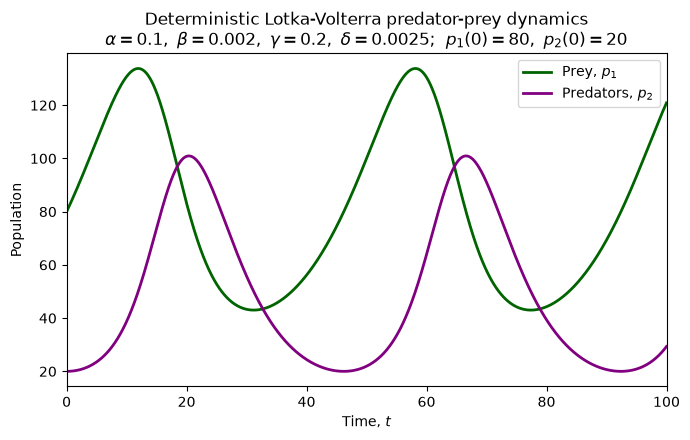

In [5]:
alpha, beta, gamma, delta = 0.1, 0.002, 0.2, 0.0025
p_1_o, p_2_o = 80, 20 # initial prey, predators
t_max, dt = 100, 0.0001

t, p_1, p_2 = deterministic_lotka_volterra(p_1_o, p_2_o, alpha, beta, gamma, delta, t_max, dt)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(t, p_1, linewidth=2, color="darkgreen", label=r"Prey, $p_1$")
ax.plot(t, p_2, linewidth=2, color="purple", label=r"Predators, $p_2$")
ax.set_xlabel(r"Time, $t$")
ax.set_ylabel("Population")
ax.set_title("Deterministic Lotka-Volterra predator-prey dynamics\n"
             rf"$\alpha={alpha},\ \beta={beta},\ \gamma={gamma},\ \delta={delta}$;  "
             rf"$p_1(0)={p_1_o},\ p_2(0)={p_2_o}$")
ax.set_xlim(0, t_max)
ax.legend()
fig.tight_layout()
fig.savefig("figures/q1a_lotka_volterra.png", dpi=300)
plt.show()

1.b

Total extinction: p_1 in [0.00134, 80], p_2 in [4.58e-08, 20], final (p_1, p_2) = (0.00134, 4.58e-08)
Predator extinction, unbounded prey growth: p_1 in [80, 1.44e+06], p_2 in [4.12e-08, 20], final (p_1, p_2) = (1.44e+06, 4.12e-08)
Steady coexistence: p_1 in [80, 80], p_2 in [20, 20], final (p_1, p_2) = (80, 20)
Neutral cycles (1.a rates): p_1 in [43, 134], p_2 in [20, 101], final (p_1, p_2) = (121, 29.3)


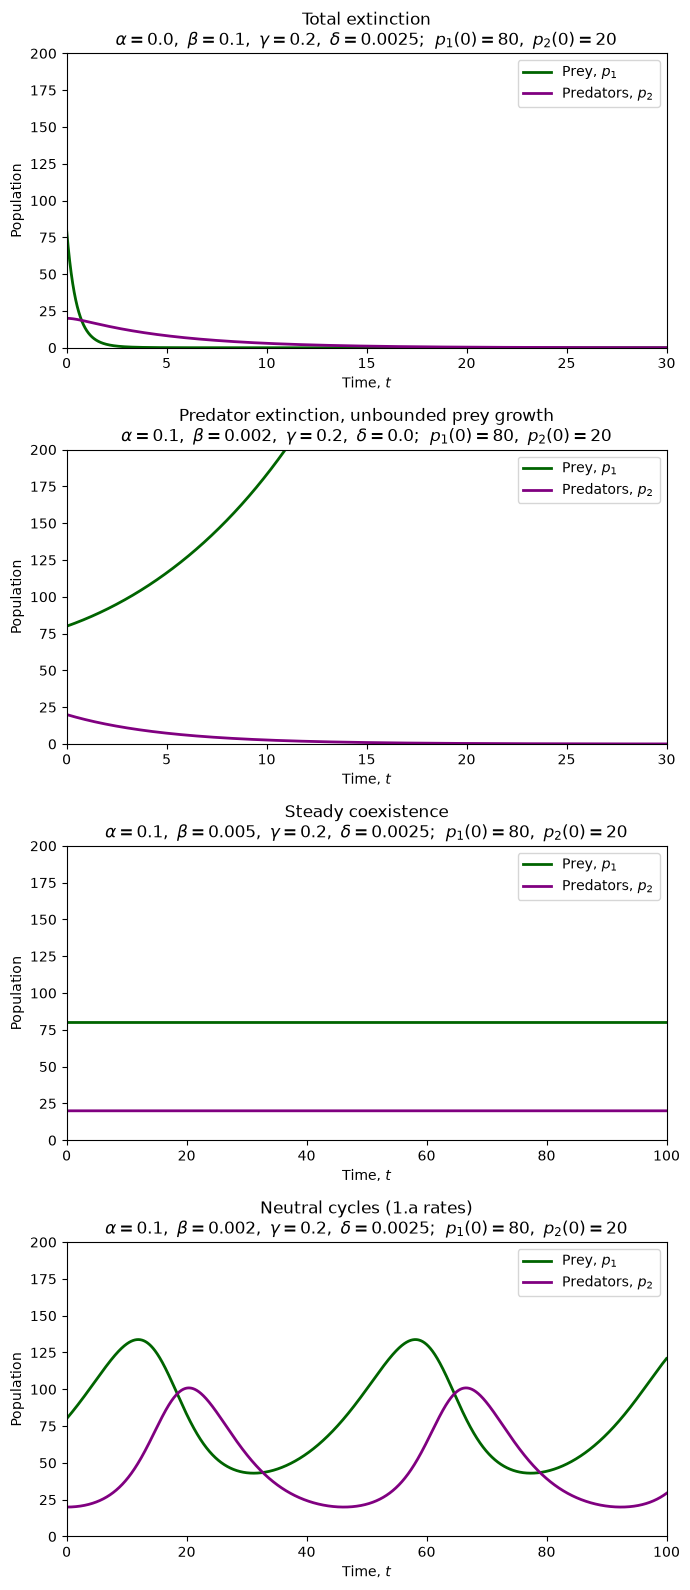

In [12]:
# 1.b same starting populations as 1.a, only rates change
p_1_o, p_2_o = 80, 20 
t_max, dt = 100, 0.0001

# title, alpha, beta, gamma, delta, x-axis limit
cases = [
    ("Total extinction", 0.0, 0.1, 0.2, 0.0025, 30),
    ("Predator extinction, unbounded prey growth", 0.1, 0.002, 0.2, 0.0, 30),
    ("Steady coexistence", 0.1, 0.005, 0.2, 0.0025, 100),
    ("Neutral cycles (1.a rates)", 0.1, 0.002, 0.2, 0.0025, 100),
]

fig, axes = plt.subplots(4, 1, figsize=(7, 16))
for ax, (name, alpha, beta, gamma, delta, x_max) in zip(axes, cases):
    t, p_1, p_2 = deterministic_lotka_volterra(p_1_o, p_2_o, alpha, beta, gamma, delta, t_max, dt)
    print(f"{name}: p_1 in [{p_1.min():.3g}, {p_1.max():.3g}], p_2 in [{p_2.min():.3g}, {p_2.max():.3g}], "
          f"final (p_1, p_2) = ({p_1[-1]:.3g}, {p_2[-1]:.3g})")

    ax.plot(t, p_1, linewidth=2, color="darkgreen", label=r"Prey, $p_1$")
    ax.plot(t, p_2, linewidth=2, color="purple", label=r"Predators, $p_2$")
    ax.set_xlabel(r"Time, $t$")
    ax.set_ylabel("Population")
    ax.set_title(f"{name}\n"
                 rf"$\alpha={alpha},\ \beta={beta},\ \gamma={gamma},\ \delta={delta}$;  "
                 rf"$p_1(0)={p_1_o},\ p_2(0)={p_2_o}$")
    ax.set_xlim(0, x_max)
    ax.set_ylim(0, 200)
    ax.legend()

fig.tight_layout()
fig.savefig("figures/q1b_outcomes.png", dpi=300)
plt.show()

p_1 in [50, 120], p_2 in [25.2, 87.5]


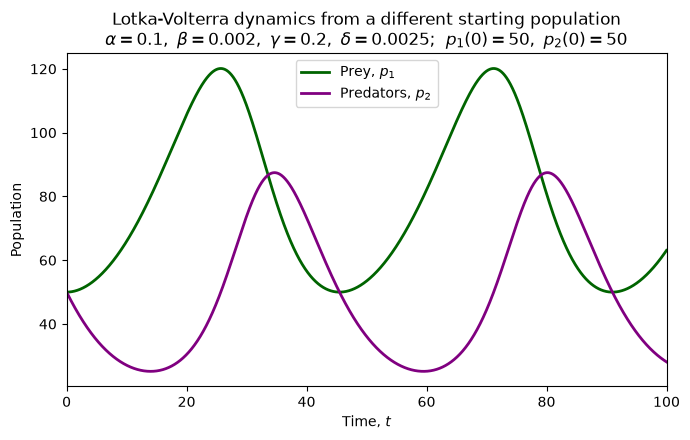

In [7]:
# example with a different starting population, back to the 1.a rates
alpha, beta, gamma, delta = 0.1, 0.002, 0.2, 0.0025
p_1_o, p_2_o = 50, 50 # initial prey, predators
t_max, dt = 100, 0.0001

t, p_1, p_2 = deterministic_lotka_volterra(p_1_o, p_2_o, alpha, beta, gamma, delta, t_max, dt)
print(f"p_1 in [{p_1.min():.3g}, {p_1.max():.3g}], p_2 in [{p_2.min():.3g}, {p_2.max():.3g}]")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(t, p_1, linewidth=2, color="darkgreen", label=r"Prey, $p_1$")
ax.plot(t, p_2, linewidth=2, color="purple", label=r"Predators, $p_2$")
ax.set_xlabel(r"Time, $t$")
ax.set_ylabel("Population")
ax.set_title("Lotka-Volterra dynamics from a different starting population\n"
             rf"$\alpha={alpha},\ \beta={beta},\ \gamma={gamma},\ \delta={delta}$;  "
             rf"$p_1(0)={p_1_o},\ p_2(0)={p_2_o}$")
ax.set_xlim(0, t_max)
ax.set_ylim(0, 200)
ax.legend()
fig.tight_layout()
fig.savefig("figures/q1b_varied_start.png", dpi=300)
plt.show()

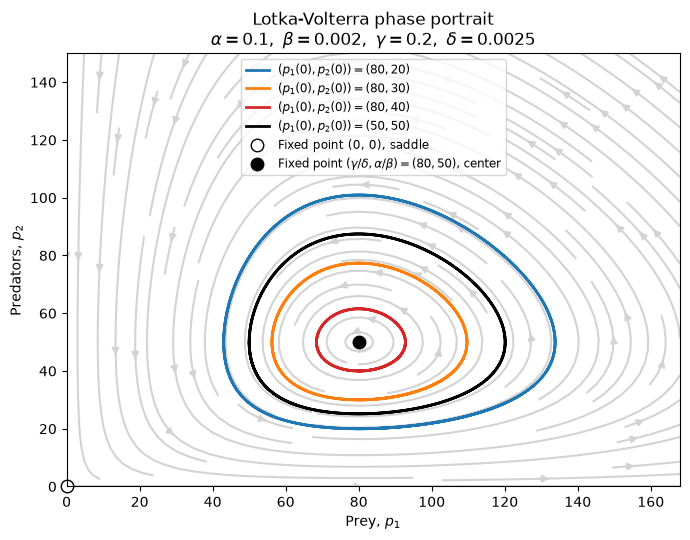

In [8]:
# phase portrait for the 1.a rates
alpha, beta, gamma, delta = 0.1, 0.002, 0.2, 0.0025
t_max, dt = 100, 0.0001

# vector field: meshgrid + streamplot taken from Sayama, phasespace-drawing-streamplot.py,
# with x -> p_1, y -> p_2 and the Lotka-Volterra right-hand sides
p_1_grid, p_2_grid = np.meshgrid(np.arange(0, 170, 2), np.arange(0, 152, 2))
p_1_dot = alpha * p_1_grid - beta * p_1_grid * p_2_grid
p_2_dot = delta * p_1_grid * p_2_grid - gamma * p_2_grid

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.streamplot(p_1_grid, p_2_grid, p_1_dot, p_2_dot, color="lightgray", density=1.2)

# orbits from several starting points, looping over initial conditions as in
# Sayama, phasespace-drawing.py 
starts = [(80, 20), (80, 30), (80, 40), (50, 50)]
colors = ["tab:blue", "tab:orange", "tab:red", "black"]
for (p_1_o, p_2_o), color in zip(starts, colors):
    t, p_1, p_2 = deterministic_lotka_volterra(p_1_o, p_2_o, alpha, beta, gamma, delta, t_max, dt)
    ax.plot(p_1, p_2, linewidth=2, color=color, label=rf"$(p_1(0), p_2(0)) = ({p_1_o}, {p_2_o})$")

# add in fixed points, saddles, etc
ax.plot(0, 0, "o", markersize=9, markerfacecolor="white", markeredgecolor="black", clip_on=False,
        label="Fixed point (0, 0), saddle")
ax.plot(gamma / delta, alpha / beta, "o", markersize=9, color="black",
        label=rf"Fixed point $(\gamma/\delta, \alpha/\beta) = ({gamma/delta:.0f}, {alpha/beta:.0f})$, center")

ax.set_xlabel(r"Prey, $p_1$")
ax.set_ylabel(r"Predators, $p_2$")
ax.set_title("Lotka-Volterra phase portrait\n"
             rf"$\alpha={alpha},\ \beta={beta},\ \gamma={gamma},\ \delta={delta}$")
ax.set_xlim(0, 168)
ax.set_ylim(0, 150)
ax.legend(fontsize="small")
fig.tight_layout()
fig.savefig("figures/q1b_phase_portrait.png", dpi=300)
plt.show()